# India-wide Groundwater Intelligence Platform
## Milestone 3: Data Ingestion, Cleaning & Quality-Flagging Forensic Analysis

**Authors:** Senior Data Engineering & Hydrogeology Team  
**Governing Standard:** `instruction.md` (Strictly read-only, non-destructive, zero synthetic data)

---

### Objectives
This notebook visually demonstrates the empirical findings and quality transformations applied during Milestone 3:
1. **Dataset Sizes:** 1,569,168 India seasonal observations across 6 CSVs + 218,791 Maharashtra 6-hourly telemetry records.
2. **Temporal Coverage:** Multi-decadal seasonal surveys (1994–2024) vs contemporary continuous telemetry (2026).
3. **Missing Value Profiling:** Column-by-column missing data analysis.
4. **Duplicate Analysis:** Exact duplicates vs conflicting measurements at the same site and date.
5. **Coordinate Validation & Inversion Proof:** Visual evidence of inverted lat/lng headers in `output1final.csv` and verified correction.
6. **Geographic Anomalies:** Concatenated administrative strings in Union Territories.
7. **Water Level Distributions:** Seasonal physical recharge/drawdown boxplots and extreme outlier identification.
8. **Quality Flags & Analytics Readiness:** Non-destructive quality tagging with zero raw record deletion.

In [1]:
# Environment Setup & Path Resolution (Supports Local and Google Colab)
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

# Configure aesthetic visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['figure.dpi'] = 120

# Robust dynamic project root resolution (Supports Local Antigravity IDE, Jupyter, and Google Colab)
def resolve_project_paths():
    search_dirs = [
        os.getcwd(),
        os.path.abspath(os.path.join(os.getcwd(), '..')),
        os.path.abspath(os.path.join(os.getcwd(), '..', '..')),
        os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..')),
    ]
    # Check immediate subdirectories of cwd (e.g. if running in /content or container root)
    try:
        for sub in os.listdir(os.getcwd()):
            sub_path = os.path.join(os.getcwd(), sub)
            if os.path.isdir(sub_path) and sub_path not in search_dirs:
                search_dirs.append(sub_path)
    except OSError:
        pass

    # Probe common Google Colab / cloud environment clone and mount locations
    for colab_dir in ['/content', '/content/DWLR_GRW_INDIA', '/content/drive/MyDrive/DWLR_GRW_INDIA']:
        if os.path.isdir(colab_dir) and colab_dir not in search_dirs:
            search_dirs.append(colab_dir)
            try:
                for sub in os.listdir(colab_dir):
                    sub_path = os.path.join(colab_dir, sub)
                    if os.path.isdir(sub_path) and sub_path not in search_dirs:
                        search_dirs.append(sub_path)
            except OSError:
                pass

    # 1. Primary check: Search for directory containing data_quality_report.json
    for d in search_dirs:
        if os.path.isfile(os.path.join(d, 'NEW', 'docs', 'data_quality_report.json')):
            base = os.path.join(d, 'NEW')
            return base, os.path.join(base, 'docs'), os.path.join(base, 'data', 'processed'), os.path.join(base, 'data', 'raw')
        if os.path.isfile(os.path.join(d, 'docs', 'data_quality_report.json')):
            return d, os.path.join(d, 'docs'), os.path.join(d, 'data', 'processed'), os.path.join(d, 'data', 'raw')

    # 2. Secondary fallback: Search for directory structure (NEW/docs or docs)
    for d in search_dirs:
        if os.path.isdir(os.path.join(d, 'NEW', 'docs')):
            base = os.path.join(d, 'NEW')
            return base, os.path.join(base, 'docs'), os.path.join(base, 'data', 'processed'), os.path.join(base, 'data', 'raw')
        if os.path.isdir(os.path.join(d, 'docs')) and os.path.isdir(os.path.join(d, 'data')):
            return d, os.path.join(d, 'docs'), os.path.join(d, 'data', 'processed'), os.path.join(d, 'data', 'raw')

    # 3. Default relative fallback
    if os.path.exists('../docs'):
        base = os.path.abspath('..')
    elif os.path.exists('NEW/docs'):
        base = os.path.abspath('NEW')
    else:
        base = os.path.abspath('.')
    return base, os.path.join(base, 'docs'), os.path.join(base, 'data', 'processed'), os.path.join(base, 'data', 'raw')

BASE_DIR, DOCS_DIR, DATA_DIR, RAW_DIR = resolve_project_paths()

print(f'Base Directory: {os.path.abspath(BASE_DIR)}')
print(f'Processed Data: {os.path.abspath(DATA_DIR)}')
print(f'Documentation:  {os.path.abspath(DOCS_DIR)}')

# Validation: Confirm data_quality_report.json is located before proceeding
report_file = os.path.join(DOCS_DIR, 'data_quality_report.json')
if not os.path.isfile(report_file):
    raise FileNotFoundError(
        f"Unable to locate data_quality_report.json at '{report_file}'.\n"
        f"Resolved DOCS_DIR: '{DOCS_DIR}'\n"
        f"Current working directory: '{os.getcwd()}'"
    )
print(f'[Verified] Located quality report: {os.path.abspath(report_file)}')


Base Directory: d:\Projects ALL\DWLR_GRW_INDIA\NEW
Processed Data: d:\Projects ALL\DWLR_GRW_INDIA\NEW\data\processed
Documentation:  d:\Projects ALL\DWLR_GRW_INDIA\NEW\docs
[Verified] Located quality report: d:\Projects ALL\DWLR_GRW_INDIA\NEW\docs\data_quality_report.json


---
## 1. Raw Dataset Ingestion & Sizes
We ingest 6 separate seasonal CSV files for India and 1 continuous telemetry file for Maharashtra.

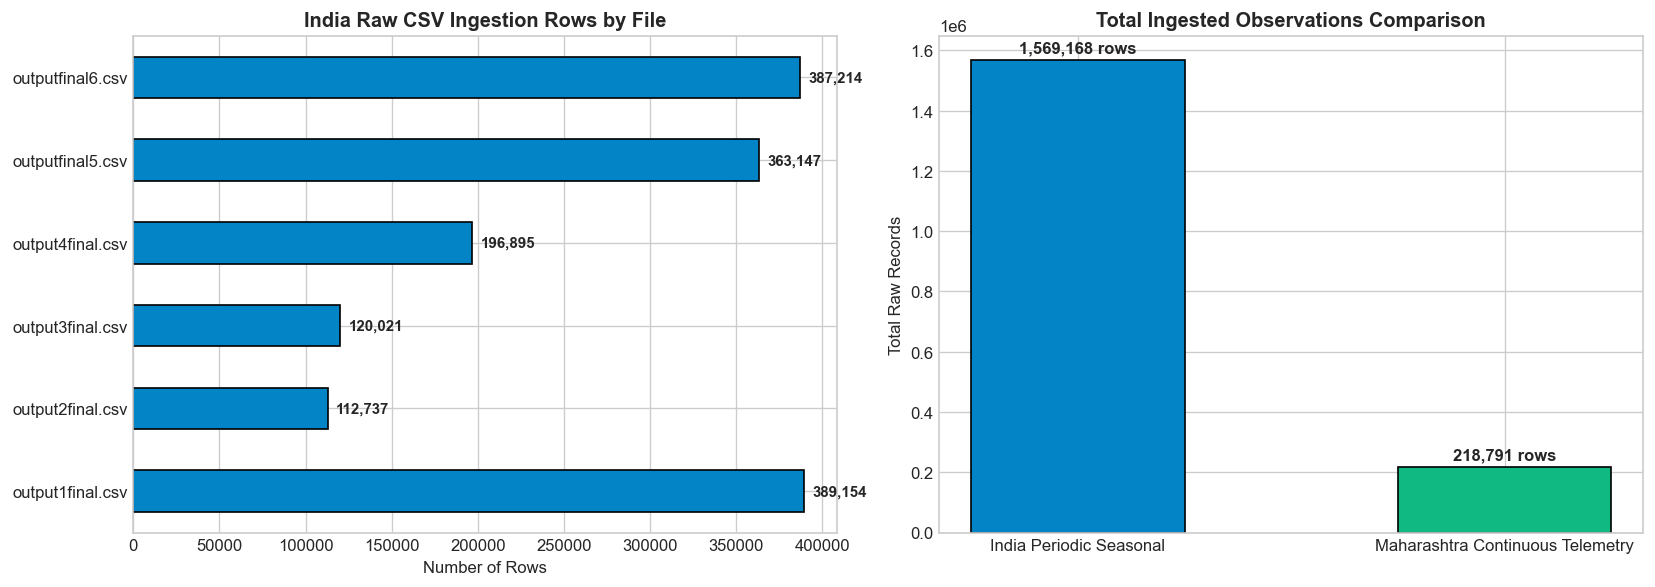

In [2]:
# Load Quality Report Summary
report_path = os.path.join(DOCS_DIR, "data_quality_report.json")
with open(report_path, "r", encoding="utf-8") as f:
    quality_report = json.load(f)

ind_summary = quality_report["india_summary"]
mh_summary = quality_report["maharashtra_summary"]

# Plot Raw Ingestion Breakdown
files_dict = ind_summary["files_breakdown"]
files_series = pd.Series(files_dict)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# India file sizes
files_series.plot(kind='barh', ax=ax1, color='#0284c7', edgecolor='black')
ax1.set_title("India Raw CSV Ingestion Rows by File")
ax1.set_xlabel("Number of Rows")
for i, v in enumerate(files_series):
    ax1.text(v + 5000, i, f"{v:,}", va='center', fontweight='bold', fontsize=9)

# Summary Comparison
categories = ['India Periodic Seasonal', 'Maharashtra Continuous Telemetry']
counts = [ind_summary['total_input_rows'], mh_summary['total_input_rows']]
colors = ['#0284c7', '#10b981']

bars = ax2.bar(categories, counts, color=colors, edgecolor='black', width=0.5)
ax2.set_title("Total Ingested Observations Comparison")
ax2.set_ylabel("Total Raw Records")
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 25000, f"{yval:,} rows", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

---
## 2. Temporal Coverage & Observation Granularity
Forensic analysis revealed that the India dataset represents **periodic seasonal observations** across 4 specific seasonal monitoring windows (Jan, Apr/May, Aug, Nov) spanning 1994 to 2024.

Loading d:\Projects ALL\DWLR_GRW_INDIA\NEW\data\processed\india\india_normalized.parquet...


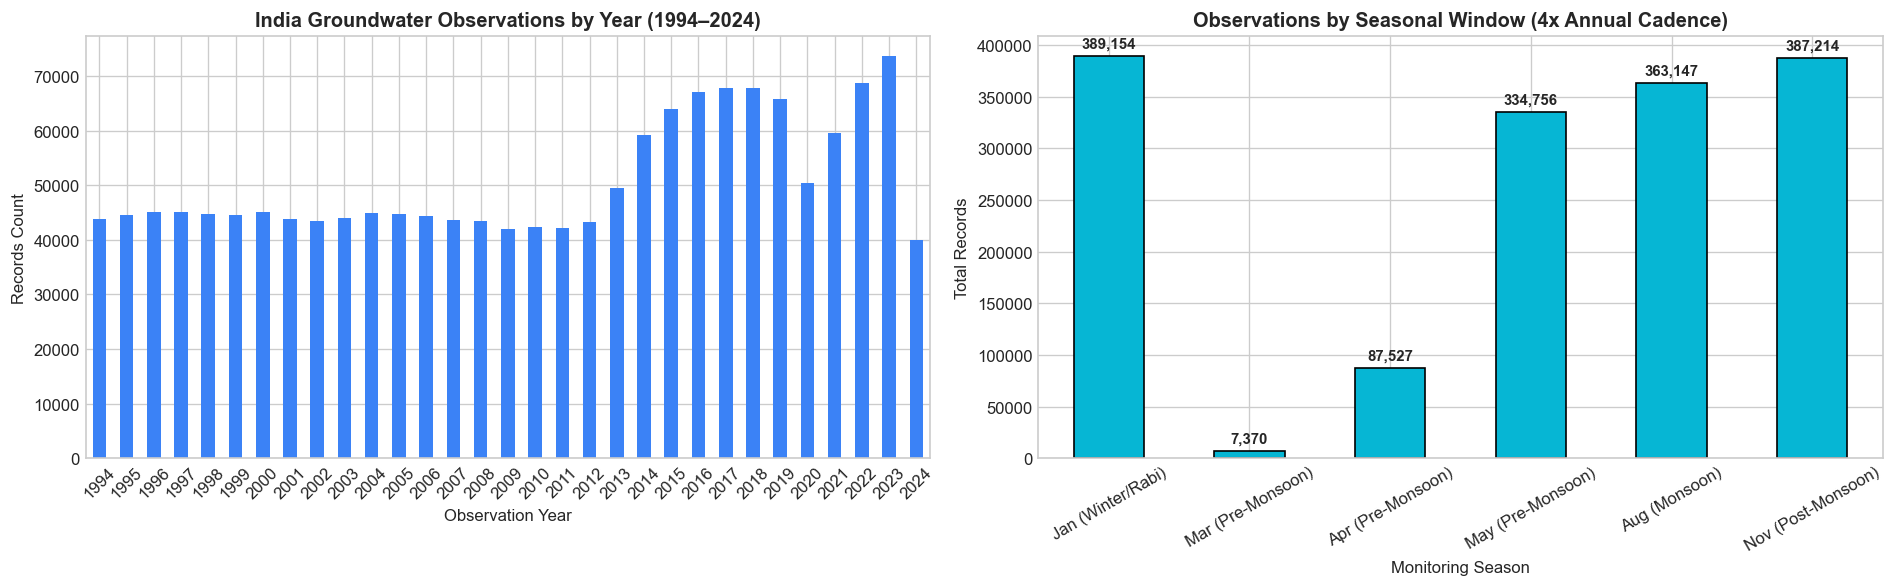

In [3]:
# Load Processed India Dataset (Parquet)
india_parquet = os.path.join(DATA_DIR, "india", "india_normalized.parquet")
print(f"Loading {india_parquet}...")
df_india = pd.read_parquet(india_parquet)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Observations by Year
year_counts = df_india['observation_year'].value_counts().sort_index()
year_counts.plot(kind='bar', ax=ax1, color='#3b82f6', edgecolor='none')
ax1.set_title("India Groundwater Observations by Year (1994–2024)")
ax1.set_xlabel("Observation Year")
ax1.set_ylabel("Records Count")
ax1.tick_params(axis='x', rotation=45)

# Observations by Seasonal Month
month_labels = {1: 'Jan (Winter/Rabi)', 3: 'Mar (Pre-Monsoon)', 4: 'Apr (Pre-Monsoon)', 
                5: 'May (Pre-Monsoon)', 8: 'Aug (Monsoon)', 11: 'Nov (Post-Monsoon)'}
month_counts = df_india['observation_month'].value_counts().sort_index()
month_counts.index = [month_labels.get(m, f"Month {m}") for m in month_counts.index]

month_counts.plot(kind='bar', ax=ax2, color='#06b6d4', edgecolor='black')
ax2.set_title("Observations by Seasonal Window (4x Annual Cadence)")
ax2.set_xlabel("Monitoring Season")
ax2.set_ylabel("Total Records")
ax2.tick_params(axis='x', rotation=30)
for i, v in enumerate(month_counts):
    ax2.text(i, v + 8000, f"{v:,}", ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

---
## 3. Missing Value Profiling
We assess missingness across administrative hierarchy, geographic coordinates, and measurement fields.

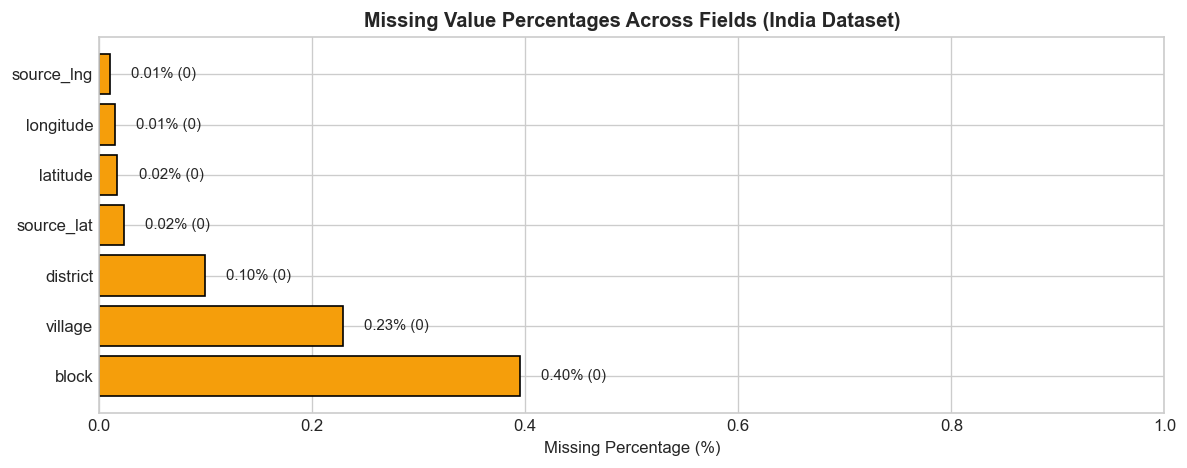

In [4]:
# Profile Missingness in India Dataset
missing_counts = df_india.isnull().sum()
missing_pct = (missing_counts / len(df_india) * 100).round(3)
missing_df = pd.DataFrame({'Missing Rows': missing_counts, 'Percentage (%)': missing_pct})
missing_df = missing_df[missing_df['Missing Rows'] > 0].sort_values('Missing Rows', ascending=False)

plt.figure(figsize=(10, 4))
bars = plt.barh(missing_df.index, missing_df['Percentage (%)'], color='#f59e0b', edgecolor='black')
plt.title("Missing Value Percentages Across Fields (India Dataset)")
plt.xlabel("Missing Percentage (%)")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.02, bar.get_y() + bar.get_height()/2, f"{w:.2f}% ({int(missing_df.loc[bar.get_y(), 'Missing Rows'] if bar.get_y() in missing_df.index else 0):,})", va='center', fontsize=9)
plt.xlim(0, max(missing_df['Percentage (%)'].max() * 1.3, 1))
plt.tight_layout()
plt.show()

---
## 4. Coordinate Validation & Inversion Proof
Forensics in Milestone 2 proved that `output1final.csv` (January observations) has inverted coordinate headers (`lat` contains Longitudes 68°E–96°E, `lng` contains Latitudes 8°N–34°N).  
Here is the visual before-and-after proof.

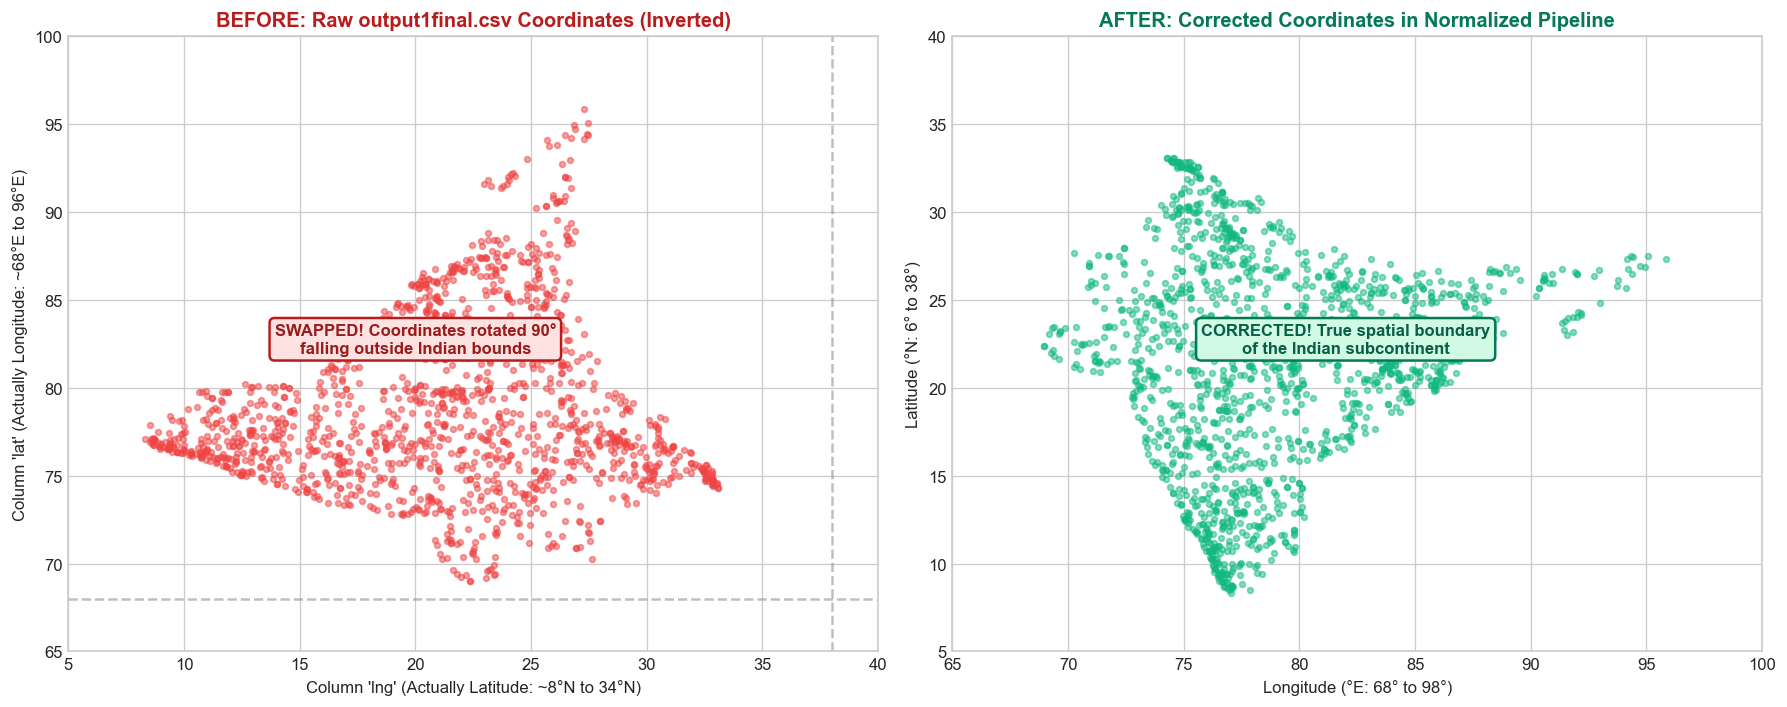

In [5]:
# Extract a sample of output1final.csv records
output1_mask = df_india['source_file'] == 'output1final.csv'
df_out1_sample = df_india[output1_mask].sample(1500, random_state=42)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# BEFORE CORRECTION: Raw source_lat (X) vs source_lng (Y)
ax1.scatter(df_out1_sample['source_lng'], df_out1_sample['source_lat'], color='#ef4444', alpha=0.5, s=12)
ax1.set_title("BEFORE: Raw output1final.csv Coordinates (Inverted)", color='#b91c1c')
ax1.set_xlabel("Column 'lng' (Actually Latitude: ~8°N to 34°N)")
ax1.set_ylabel("Column 'lat' (Actually Longitude: ~68°E to 96°E)")
ax1.set_xlim(5, 40)
ax1.set_ylim(65, 100)
ax1.axhline(68, color='gray', linestyle='--', alpha=0.5)
ax1.axvline(38, color='gray', linestyle='--', alpha=0.5)
ax1.text(20, 82, "SWAPPED! Coordinates rotated 90°\nfalling outside Indian bounds", ha='center', fontweight='bold', color='#991b1b', bbox=dict(boxstyle="round,pad=0.3", fc="#fee2e2", ec="#b91c1c", lw=1.5))

# AFTER CORRECTION: Corrected Longitude (X) vs Latitude (Y)
ax2.scatter(df_out1_sample['longitude'], df_out1_sample['latitude'], color='#10b981', alpha=0.5, s=12)
ax2.set_title("AFTER: Corrected Coordinates in Normalized Pipeline", color='#047857')
ax2.set_xlabel("Longitude (°E: 68° to 98°)")
ax2.set_ylabel("Latitude (°N: 6° to 38°)")
ax2.set_xlim(65, 100)
ax2.set_ylim(5, 40)
ax2.text(82, 22, "CORRECTED! True spatial boundary\nof the Indian subcontinent", ha='center', fontweight='bold', color='#065f46', bbox=dict(boxstyle="round,pad=0.3", fc="#d1fae5", ec="#047857", lw=1.5))

plt.tight_layout()
plt.show()

---
## 5. Malformed Administrative Records
In Union Territories, administrative hierarchy fields were fused together during data generation into the `state` column. Our pipeline non-destructively flags them with `MALFORMED_ADMIN_GEOGRAPHY`.

In [6]:
# Inspect malformed administrative geography records
malformed_mask = df_india['quality_flags'].str.contains('MALFORMED_ADMIN_GEOGRAPHY')
df_malformed = df_india[malformed_mask]

print(f"Total records flagged with MALFORMED_ADMIN_GEOGRAPHY: {len(df_malformed):,}")
print("\nTop 5 Concatenated State Strings:")
for s, count in df_malformed['state'].value_counts().head(5).items():
    print(f"  - Count: {count:3d} | '{s[:75]}...'")

Total records flagged with MALFORMED_ADMIN_GEOGRAPHY: 1,318

Top 5 Concatenated State Strings:
  - Count: 347 | 'The Dadra And Nagar Haveli And Daman And DiuDaman...'
  - Count: 182 | 'The Dadra And Nagar Haveli And Daman And DiuDiu...'
  - Count: 174 | 'The Dadra And Nagar Haveli And Daman And DiuDaman Daman...'
  - Count: 135 | 'Dadra Nagar Haveli & Daman DiuDadra And Nagar Haveli Dadra Nagar Haveli...'
  - Count:  34 | 'The Dadra And Nagar Haveli And Daman And DiuDadra And Nagar Haveli Dadra Na...'


---
## 6. Groundwater Level Distributions & Extreme Values
We profile the physical behavior of groundwater levels across seasons, and identify extreme measurement errors.

C:\Users\Yogesh\AppData\Local\Temp\ipykernel_22852\974980273.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sample_seasonal, x='observation_month', y='water_level_raw', ax=ax1, palette='Blues_r', order=season_order)
C:\Users\Yogesh\AppData\Local\Temp\ipykernel_22852\974980273.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(season_names)


Total records with water_level > 150m: 162
Top 3 Extreme Anomalies in Assam (flagged as SEVERE_EXTREME_WATER_LEVEL_REVIEW_REQUIRED):
  - State: Assam | Village: Panbari | Date: 2004-11-01 | water_level_raw: 53943.6 (unit: UNKNOWN)
  - State: Assam | Village: Bagaribari | Date: 2004-11-01 | water_level_raw: 27606.5 (unit: UNKNOWN)
  - State: Assam | Village: Chalantapara | Date: 2004-11-01 | water_level_raw: 2839.8 (unit: UNKNOWN)


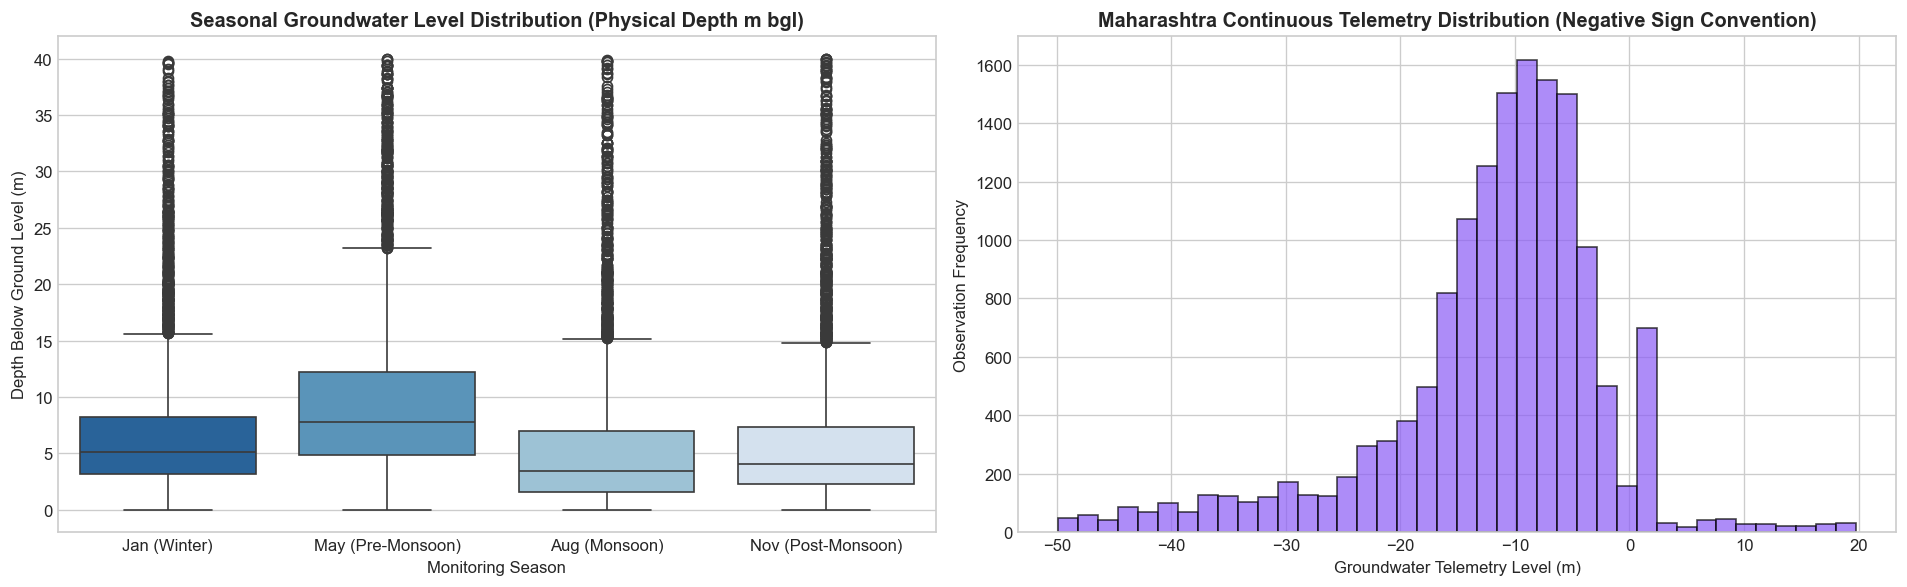

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Seasonal Water Level Boxplot (Filtered for plausible physical depths < 50m)
season_order = [1, 5, 8, 11]
season_names = ['Jan (Winter)', 'May (Pre-Monsoon)', 'Aug (Monsoon)', 'Nov (Post-Monsoon)']
sample_seasonal = df_india[(df_india['water_level_raw'] >= 0) & (df_india['water_level_raw'] <= 40) & (df_india['observation_month'].isin(season_order))].sample(20000, random_state=42)

sns.boxplot(data=sample_seasonal, x='observation_month', y='water_level_raw', ax=ax1, palette='Blues_r', order=season_order)
ax1.set_xticklabels(season_names)
ax1.set_title("Seasonal Groundwater Level Distribution (Physical Depth m bgl)")
ax1.set_xlabel("Monitoring Season")
ax1.set_ylabel("Depth Below Ground Level (m)")

# Extreme Outliers in Source Data
extreme_mask = df_india['water_level_raw'] > 150
extreme_records = df_india[extreme_mask].sort_values('water_level_raw', ascending=False)
print(f"Total records with water_level > 150m: {len(extreme_records):,}")
print("Top 3 Extreme Anomalies in Assam (flagged as SEVERE_EXTREME_WATER_LEVEL_REVIEW_REQUIRED):")
for idx, r in extreme_records.head(3).iterrows():
    print(f"  - State: {r['state']} | Village: {r['village']} | Date: {r['observation_date']} | water_level_raw: {r['water_level_raw']} (unit: {r['water_level_unit']})")

# Histogram of Maharashtra Telemetry
mh_parquet = os.path.join(DATA_DIR, "maharashtra", "maharashtra_normalized.parquet")
df_mh = pd.read_parquet(mh_parquet)
sample_mh = df_mh[(df_mh['water_level_raw'] >= -50) & (df_mh['water_level_raw'] <= 20)].sample(15000, random_state=42)

ax2.hist(sample_mh['water_level_raw'], bins=40, color='#8b5cf6', edgecolor='black', alpha=0.7)
ax2.set_title("Maharashtra Continuous Telemetry Distribution (Negative Sign Convention)")
ax2.set_xlabel("Groundwater Telemetry Level (m)")
ax2.set_ylabel("Observation Frequency")

plt.tight_layout()
plt.show()

---
## 7. Quality Flags Distribution & Duplicate Analysis
Every quality issue is explicitly tagged with standardized flags without altering the underlying raw data.

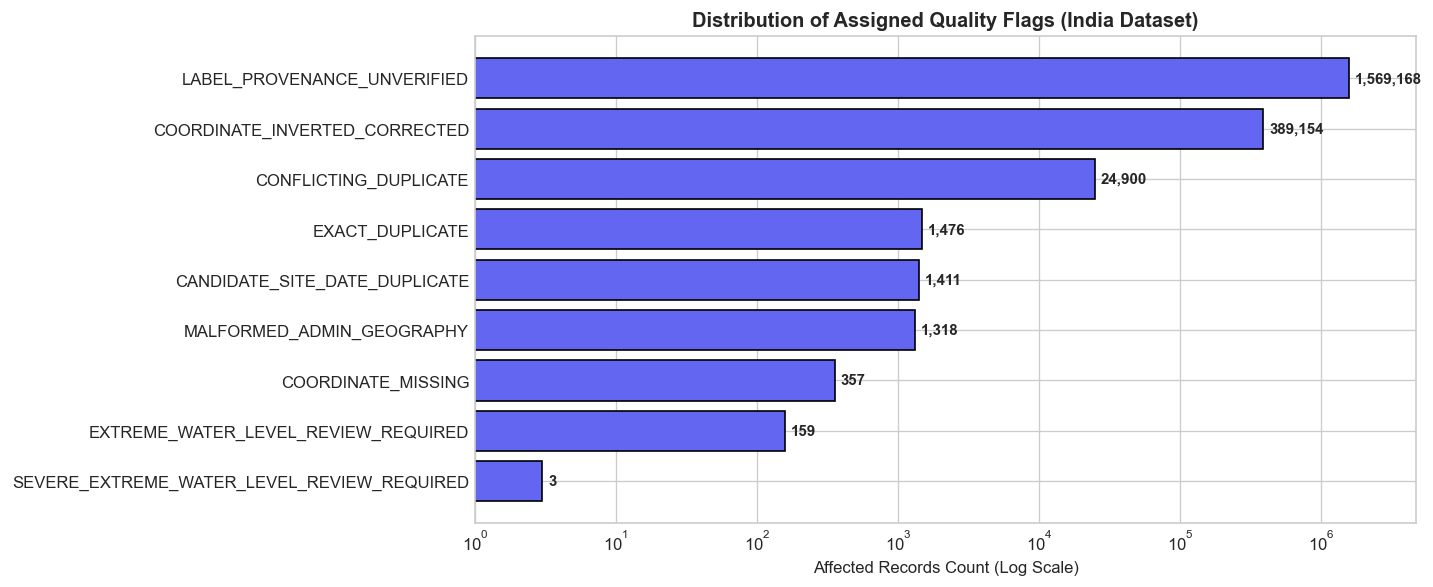

In [8]:
# Quality Flag Frequency Bar Chart
flags_series = pd.Series(ind_summary['quality_flag_counts']).sort_values()

plt.figure(figsize=(12, 5))
bars = plt.barh(flags_series.index, flags_series.values, color='#6366f1', edgecolor='black')
plt.title("Distribution of Assigned Quality Flags (India Dataset)")
plt.xlabel("Affected Records Count (Log Scale)")
plt.xscale('log')

for bar in bars:
    val = bar.get_width()
    plt.text(val * 1.1, bar.get_y() + bar.get_height()/2, f"{int(val):,}", va='center', fontweight='bold', fontsize=9)

plt.xlim(1, max(flags_series.values) * 3)
plt.tight_layout()
plt.show()

---
## 8. Before-vs-After Retention & Analytics Readiness
The pipeline strictly enforces 100% data retention (0 rows dropped). Records with quality defects are segregated for analytics using `is_analytics_ready`.

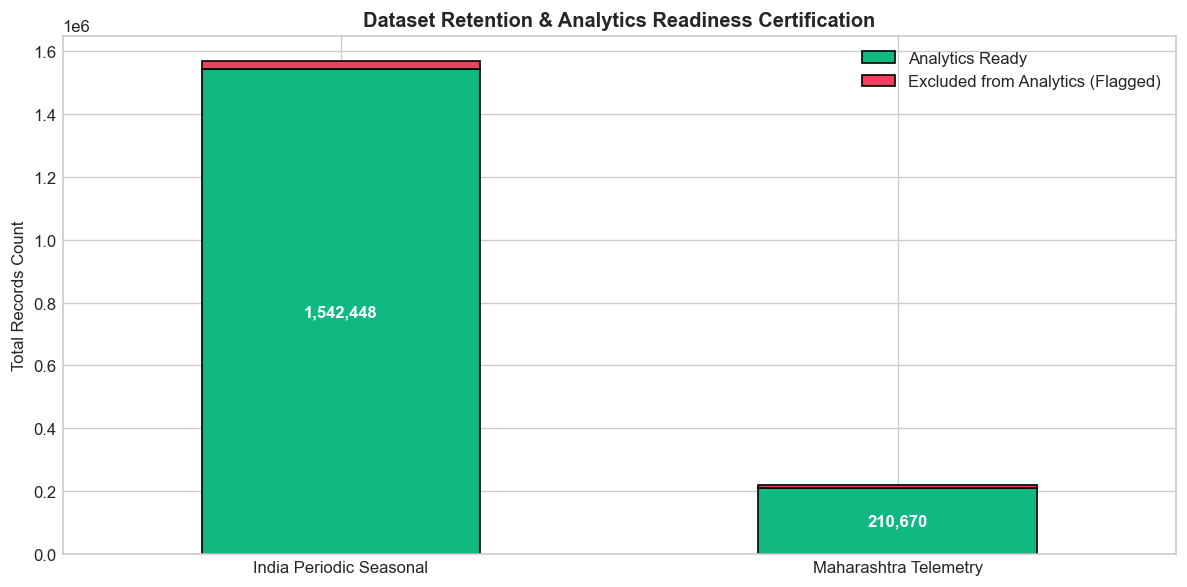

In [9]:
# Readiness Summary
categories = ['India Periodic Seasonal', 'Maharashtra Telemetry']
ready_counts = [ind_summary['analytics_ready_rows'], mh_summary['analytics_ready_rows']]
excluded_counts = [ind_summary['excluded_from_analytics'], mh_summary['excluded_from_analytics']]

df_retention = pd.DataFrame({
    'Analytics Ready': ready_counts,
    'Excluded from Analytics (Flagged)': excluded_counts
}, index=categories)

ax = df_retention.plot(kind='bar', stacked=True, figsize=(10, 5), color=['#10b981', '#f43f5e'], edgecolor='black')
plt.title("Dataset Retention & Analytics Readiness Certification")
plt.ylabel("Total Records Count")
plt.xticks(rotation=0)

for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    if height > 50000:
        x, y = p.get_xy() 
        ax.text(x + width/2, y + height/2, f"{int(height):,}", ha='center', va='center', color='white', fontweight='bold')

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

---
## 9. Structural Comparison: India vs. Maharashtra
Summary of architectural differences between the two ingested paradigms.

In [10]:
comparison_table = pd.DataFrame([
    {"Dimension": "Observation Paradigm", "India Dataset": "Periodic Seasonal Surveys (CGWB)", "Maharashtra Dataset": "Continuous Telemetry (GSDA)"},
    {"Dimension": "Total Records", "India Dataset": "1,569,168 rows", "Maharashtra Dataset": "218,791 rows"},
    {"Dimension": "Date Coverage", "India Dataset": "31 Years (1994 to 2024)", "Maharashtra Dataset": "5 Months (Jan to May 2026)"},
    {"Dimension": "Sampling Cadence", "India Dataset": "4x per year (Jan, Apr/May, Aug, Nov)", "Maharashtra Dataset": "6-hourly (00:00, 06:00, 12:00, 18:00)"},
    {"Dimension": "Sign Convention", "India Dataset": "100% Positive (0m to 299m)", "Maharashtra Dataset": "91.96% Negative (-1791m to +213m)"},
    {"Dimension": "Reference Datum", "India Dataset": "Presumed Depth Below Ground Level (m bgl)", "Maharashtra Dataset": "Unconfirmed Telemetry Sensor Datum"},
    {"Dimension": "Analytics-Ready Rows", "India Dataset": f"{ind_summary['analytics_ready_rows']:,} (98.30%)", "Maharashtra Dataset": f"{mh_summary['analytics_ready_rows']:,} (96.29%)"},
    {"Dimension": "Raw Immutability", "India Dataset": "100% Preserved (0 rows deleted)", "Maharashtra Dataset": "100% Preserved (0 rows deleted)"}
])

display(comparison_table)

,Dimension,India Dataset,Maharashtra Dataset
0,Observation Paradigm,Periodic Seasonal Surveys (CGWB),Continuous Telemetry (GSDA)
1,Total Records,"1,569,168 rows","218,791 rows"
2,Date Coverage,31 Years (1994 to 2024),5 Months (Jan to May 2026)
3,Sampling Cadence,"4x per year (Jan, Apr/May, Aug, Nov)","6-hourly (00:00, 06:00, 12:00, 18:00)"
4,Sign Convention,100% Positive (0m to 299m),91.96% Negative (-1791m to +213m)
5,Reference Datum,Presumed Depth Below Ground Level (m bgl),Unconfirmed Telemetry Sensor Datum
6,Analytics-Ready Rows,"1,542,448 (98.30%)","210,670 (96.29%)"
7,Raw Immutability,100% Preserved (0 rows deleted),100% Preserved (0 rows deleted)
